# Đánh giá thực nghiệm Phân hệ Dự báo Tuổi thọ Còn lại (Predictive RUL)

> **Tóm tắt phục vụ bảo vệ:** Notebook kiểm chứng trực tiếp pipeline xử lý dữ liệu đa kênh, guardrail `RUNNING`, xử lý thiếu kênh trung tính và mô hình nguyên mẫu **NumPy LSTM** (`eam_app/algorithms/predictive_rul/`) trên bộ dữ liệu tái lập `seed=42`, thể hiện rõ trạng thái nguyên mẫu chưa huấn luyện trên dữ liệu công nghiệp thực tế.

**Xác minh từ mã nguồn (`eam_app/algorithms/predictive_rul/`):**
- Trong `model.py` có định nghĩa lớp `PyTorchLSTMRULPredictor`, nhưng hàm `get_rul_model()` được gọi thực tế trong luồng suy diễn (`RULPredictiveService.predict_asset_rul`) trả về **`NumpyLSTMRULPredictor`** (mô hình LSTM 2 tầng 64→32 thuần NumPy, khởi tạo trọng số Xavier `seed=42`, `b_fc = 45.0`, kết hợp hệ số suy giảm theo độ rung và chênh lệch nhiệt độ).
- Không có mô hình **Weibull** trong phân hệ `predictive_rul`.
- Nguồn dữ liệu: `DegradationFeaturePipeline.generate_synthetic_femto_trajectory()` tạo **chuỗi suy thoái mô phỏng 100 chu kỳ theo dạng FEMTO-like** (không phải dữ liệu đo hỏng hóc thực tế tại nhà máy).
- **Chuẩn hóa xử lý đa kênh (AUD-04):** `PredictiveRULGuardrails.filter_running_meter_readings()` gom nhóm các bản ghi đồng thời theo `round_id` hoặc cửa sổ thời gian `<= 2s`, tránh gán `vibration=0.0` cho dòng nhiệt độ; kênh thiếu được giữ trung tính (`ΔT = 0.0` khi thiếu cảm biến nhiệt) thay vì giả định `45°C`.
- **Giới hạn đánh giá sai số:** Do `NumpyLSTMRULPredictor` sử dụng trọng số hiệu chuẩn khởi điểm và dự án chưa có tập dữ liệu hỏng hóc thực tế gắn nhãn RUL để huấn luyện/kiểm định, **chưa đủ điều kiện tính sai số định lượng MAE/RMSE** (tiếp tục ghi `Chưa đo` trong Bảng 3.13). Notebook này kiểm chứng hành vi suy diễn, khoảng tin cậy **MC-Dropout (`M=20`, 90% CI)**, vùng khởi động nguội (`N < 15`) và **bộ lọc suy thoái đơn điệu** trên đúng mã nguồn đang chạy.

In [1]:
import os, sys, types, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.isdir(os.path.join(REPO_ROOT, 'eam_app')):
    REPO_ROOT = r'D:\GameLinkNeverDie\eam-enterprise-assset-management'
RUL_DIR = os.path.join(REPO_ROOT, 'eam_app', 'algorithms', 'predictive_rul')

# Nạp gói predictive_rul mà không kích hoạt Django ORM trong __init__.py
pkg = types.ModuleType('predictive_rul')
pkg.__path__ = [RUL_DIR]
sys.modules['predictive_rul'] = pkg

constants = importlib.import_module('predictive_rul.constants')
model_mod = importlib.import_module('predictive_rul.model')
pipeline_mod = importlib.import_module('predictive_rul.dataset_pipeline')
guardrails_mod = importlib.import_module('predictive_rul.guardrails')

rul_model = model_mod.get_rul_model()
DegradationFeaturePipeline = pipeline_mod.DegradationFeaturePipeline
PredictiveRULGuardrails = guardrails_mod.PredictiveRULGuardrails

print('Actual inference model:', type(rul_model).__name__)
print('PyTorch class defined in model.py:', hasattr(model_mod, 'PyTorchLSTMRULPredictor'))
print('Hyperparameters: WINDOW_SIZE =', constants.WINDOW_SIZE,
      '| FEATURE_DIM =', constants.FEATURE_DIM,
      '| MC_DROPOUT_PASSES =', constants.MC_DROPOUT_PASSES,
      '| MC_DROPOUT_RATE =', constants.MC_DROPOUT_RATE,
      '| COLD_START_MIN_SAMPLES =', constants.COLD_START_MIN_SAMPLES)
import types as _types
from datetime import datetime, timedelta
print('Model metadata:', rul_model.get_model_metadata())

# Kiểm chứng gom nhóm đa kênh & xử lý thiếu kênh (AUD-04)
t0 = datetime(2026, 11, 20, 8, 0, 0)
mock_rows = [
    _types.SimpleNamespace(id='r1', round_id=None, reading_date=t0, metric_code='TEMPERATURE', reading_value=52.5, ambient_temperature=31.0, pressure=None, load_factor=1.0, machine_state='RUNNING', is_pre_repair=False, is_suppressed=False),
    _types.SimpleNamespace(id='r2', round_id=None, reading_date=t0 + timedelta(milliseconds=50), metric_code='VIBRATION', reading_value=3.2, ambient_temperature=None, pressure=None, load_factor=1.0, machine_state='RUNNING', is_pre_repair=False, is_suppressed=False),
]
grouped_test = PredictiveRULGuardrails.filter_running_meter_readings(mock_rows)
diag_test = PredictiveRULGuardrails.analyze_grouped_channel_completeness(grouped_test, raw_running_count=len(mock_rows))
missing_vec = DegradationFeaturePipeline.extract_4_feature_vector(vibration_rms=2.5, bearing_temp=None, ambient_temp=30.0, pressure=None)
print(f'Multi-channel grouping check: {len(mock_rows)} raw rows -> {len(grouped_test)} grouped cycle | observed={diag_test["observedChannels"]} | missing={diag_test["missingChannels"]}')
print(f'Missing-temp neutral check: delta_t_norm={float(missing_vec[1]):.3f}, pressure_norm={float(missing_vec[2]):.3f}')

Actual inference model: NumpyLSTMRULPredictor
PyTorch class defined in model.py: True
Hyperparameters: WINDOW_SIZE = 30 | FEATURE_DIM = 4 | MC_DROPOUT_PASSES = 20 | MC_DROPOUT_RATE = 0.2 | COLD_START_MIN_SAMPLES = 15
Model metadata: {'modelName': 'NumpyLSTMRULPredictor', 'modelVersion': 'v1.0.0-untrained-prototype', 'isTrainedOnRealData': False, 'trainingStatus': 'UNTRAINED_PROTOTYPE', 'isPrototype': True, 'calibrationNote': 'Nguyên mẫu thử nghiệm dùng NumpyLSTMRULPredictor với trọng số khởi tạo và công thức hiệu chỉnh theo độ rung/chênh lệch nhiệt; chưa được huấn luyện trên dữ liệu hỏng hóc thực tế có nhãn và chưa công bố chỉ số MAE/RMSE.'}
Multi-channel grouping check: 2 raw rows -> 1 grouped cycle | observed=['VIBRATION', 'TEMPERATURE', 'AMBIENT_TEMPERATURE'] | missing=['PRESSURE']
Missing-temp neutral check: delta_t_norm=0.000, pressure_norm=0.000


In [2]:
# ==============================================================================
# Sinh chuỗi suy thoái mô phỏng 100 chu kỳ từ DegradationFeaturePipeline
# ==============================================================================
trajectory = DegradationFeaturePipeline.generate_synthetic_femto_trajectory(
    total_cycles=100, load_factor=1.0, noise_std=0.05
)
df_traj = pd.DataFrame(trajectory)
df_traj['delta_t'] = df_traj['bearing_temperature'] - df_traj['ambient_temperature']

print(f'Tổng số chu kỳ mô phỏng: {len(df_traj)}')
print(df_traj[['cycle', 'vibration', 'bearing_temperature', 'delta_t', 'pressure', 'load_factor']].iloc[[0, 49, 69, 79, 89, 99]].to_string(index=False))

Tổng số chu kỳ mô phỏng: 100
 cycle  vibration  bearing_temperature   delta_t  pressure  load_factor
     1   1.524836            41.986174 13.986174 10.129538          1.0
    50   1.433977            42.052194 14.052194 10.059397          1.0
    70   1.525689            42.051505 14.051505 10.770546          1.0
    80   3.618189            48.260421 20.260421 10.170487          1.0
    90   8.572943            63.389347 35.389347 10.026148          1.0
   100  19.866714            97.135332 69.135332 10.125926          1.0


In [3]:
# ==============================================================================
# Chạy đúng luồng suy diễn RULPredictiveService (Cold-Start + Sliding Window + MC-Dropout M=20 + Monotonic Filter)
# ==============================================================================
np.random.seed(42)
records = []
prev_filtered_rul = None
crit_threshold = PredictiveRULGuardrails.calculate_dynamic_critical_threshold(lead_time_days=7)

for t_idx in range(len(trajectory)):
    running_slice = trajectory[:t_idx + 1]
    n_samples = len(running_slice)
    cycle_num = trajectory[t_idx]['cycle']

    is_cold, _ = PredictiveRULGuardrails.check_cold_start_bypass(n_samples)
    if is_cold:
        records.append({
            'cycle': cycle_num,
            'status': 'CALIBRATING',
            'rul_mean': np.nan,
            'rul_filtered': np.nan,
            'ci_lower': np.nan,
            'ci_upper': np.nan,
            'rul_std': np.nan
        })
        continue

    # Padding nếu 15 <= n_samples < 30 (đúng theo RULPredictiveService.predict_asset_rul dòng 113-115)
    padded = list(running_slice)
    while len(padded) < constants.WINDOW_SIZE:
        padded.insert(0, running_slice[0])

    seq = DegradationFeaturePipeline.construct_sliding_window(padded, window_size=constants.WINDOW_SIZE)

    # M=20 lượt suy diễn Monte Carlo Dropout
    mc_preds = [rul_model.forward_one_pass(seq, apply_dropout=True) for _ in range(constants.MC_DROPOUT_PASSES)]
    unc = PredictiveRULGuardrails.calculate_mc_dropout_uncertainty(mc_preds)
    rul_mean = unc['rul_mean']
    rul_filtered = PredictiveRULGuardrails.apply_monotonic_filter(
        current_rul=rul_mean,
        previous_rul=prev_filtered_rul,
        is_core_overhaul_completed=False
    )
    prev_filtered_rul = rul_filtered

    records.append({
        'cycle': cycle_num,
        'status': PredictiveRULGuardrails.evaluate_risk_level(rul_filtered, crit_threshold),
        'rul_mean': rul_mean,
        'rul_filtered': rul_filtered,
        'ci_lower': unc['confidence_lower'],
        'ci_upper': unc['confidence_upper'],
        'rul_std': unc['rul_std']
    })

df_res = pd.DataFrame(records)
valid_res = df_res.dropna(subset=['rul_mean'])
print(f'Ngưỡng Critical động (lead_time=7 ngày): {crit_threshold} ngày')
print(f'Số bước hiệu chuẩn (Cold-Start N < 15): {(df_res["status"] == "CALIBRATING").sum()} chu kỳ')
print(f'Số bước suy diễn hợp lệ: {len(valid_res)} chu kỳ')
print(f'Độ lệch chuẩn MC-Dropout trung bình: {valid_res["rul_std"].mean():.2f} ngày (min={valid_res["rul_std"].min():.2f}, max={valid_res["rul_std"].max():.2f})')
print(df_res.iloc[[0, 14, 29, 49, 69, 79, 89, 99]].to_string(index=False))

Ngưỡng Critical động (lead_time=7 ngày): 14 ngày
Số bước hiệu chuẩn (Cold-Start N < 15): 14 chu kỳ
Số bước suy diễn hợp lệ: 86 chu kỳ
Độ lệch chuẩn MC-Dropout trung bình: 0.00 ngày (min=0.00, max=0.01)
 cycle      status  rul_mean  rul_filtered  ci_lower  ci_upper  rul_std
     1 CALIBRATING       NaN           NaN       NaN       NaN      NaN
    15      MEDIUM      36.6          36.6      36.6      36.6      0.0
    30      MEDIUM      36.5          36.6      36.5      36.5      0.0
    50      MEDIUM      36.5          36.6      36.5      36.5      0.0
    70      MEDIUM      36.6          36.6      36.5      36.6      0.0
    80      MEDIUM      31.4          32.4      31.4      31.4      0.0
    90        HIGH      17.3          18.3      17.3      17.3      0.0
   100        HIGH      13.5          14.5      13.5      13.5      0.0


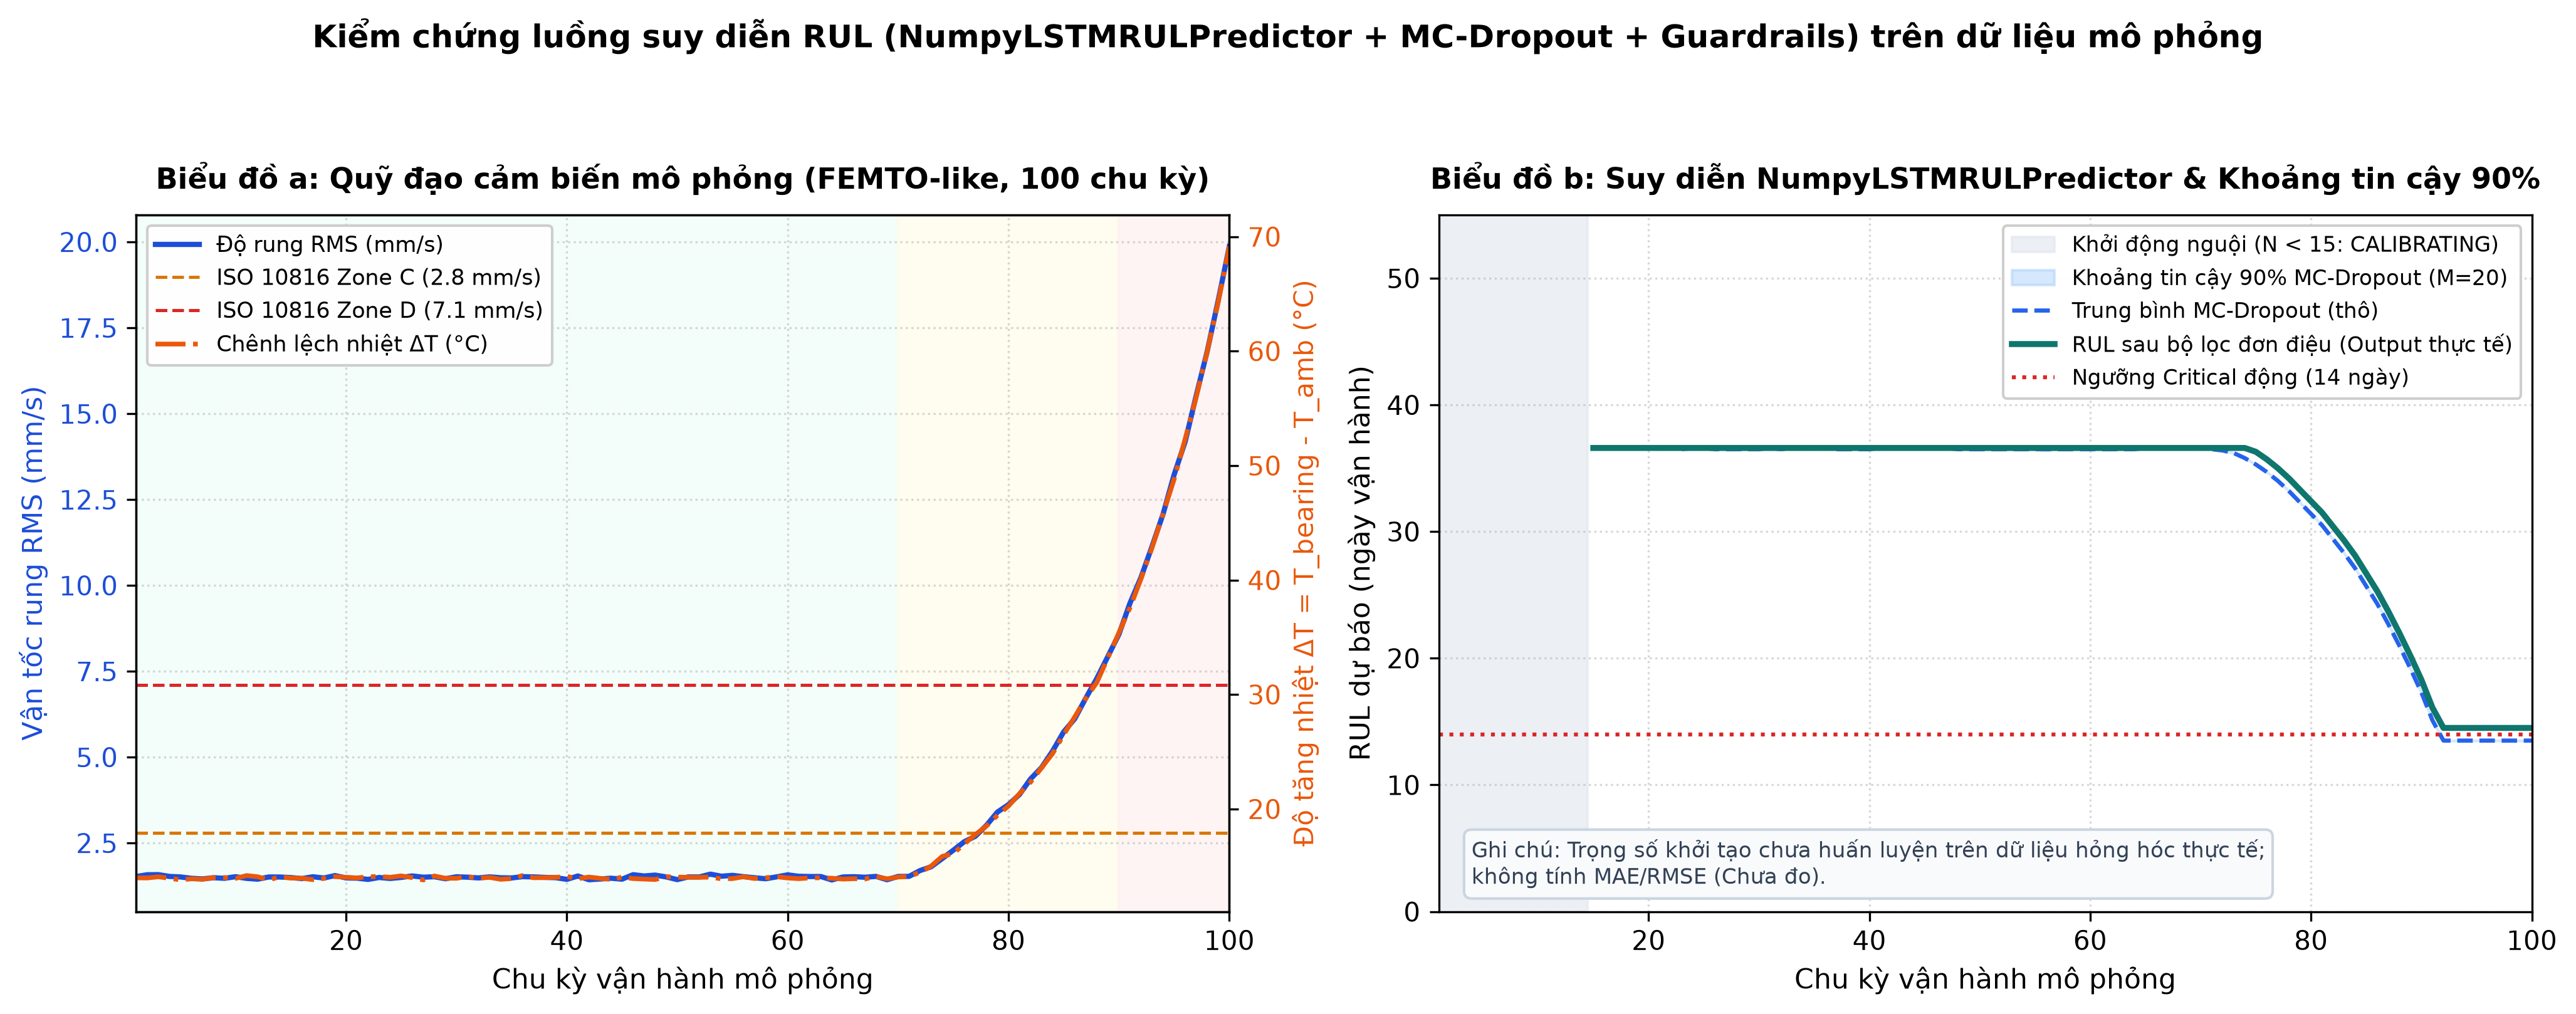

Saved figure: D:\GameLinkNeverDie\eam-enterprise-assset-management\scripts\results\figure_3_27_rul_evaluation.png size: 431127


In [4]:
# ==============================================================================
# Vẽ và lưu Hình 3.27 trực tiếp từ kết quả suy diễn thực nghiệm
# ==============================================================================
os.makedirs(os.path.join(REPO_ROOT, 'scripts', 'results'), exist_ok=True)
out_img = os.path.join(REPO_ROOT, 'scripts', 'results', 'figure_3_27_rul_evaluation.png')

plt.rcParams['font.family'] = 'DejaVu Sans'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 5.4), dpi=300)

# Biểu đồ a: Dữ liệu cảm biến đầu vào mô phỏng (Vibration RMS & Delta T)
ax1.axvspan(1, 70, color='#ecfdf5', alpha=0.6, label='Giai đoạn 1: Ổn định (0-70%)')
ax1.axvspan(70, 90, color='#fffbeb', alpha=0.7, label='Giai đoạn 2: Rỗ bề mặt (70-90%)')
ax1.axvspan(90, 100, color='#fef2f2', alpha=0.8, label='Giai đoạn 3: Suy thoái nhanh (90-100%)')

l1 = ax1.plot(df_traj['cycle'], df_traj['vibration'], color='#1d4ed8', linewidth=2.0, label='Độ rung RMS (mm/s)')
ax1.axhline(2.8, color='#d97706', linestyle='--', linewidth=1.2, label='ISO 10816 Zone C (2.8 mm/s)')
ax1.axhline(7.1, color='#dc2626', linestyle='--', linewidth=1.2, label='ISO 10816 Zone D (7.1 mm/s)')
ax1.set_xlabel('Chu kỳ vận hành mô phỏng', fontsize=10.5)
ax1.set_ylabel('Vận tốc rung RMS (mm/s)', fontsize=10.5, color='#1d4ed8')
ax1.tick_params(axis='y', labelcolor='#1d4ed8')
ax1.set_xlim(1, 100)
ax1.grid(True, linestyle=':', alpha=0.5)

ax1_r = ax1.twinx()
l2 = ax1_r.plot(df_traj['cycle'], df_traj['delta_t'], color='#ea580c', linewidth=1.8, linestyle='-.', label='Chênh lệch nhiệt ΔT (°C)')
ax1_r.set_ylabel('Độ tăng nhiệt ΔT = T_bearing - T_amb (°C)', fontsize=10.0, color='#ea580c')
ax1_r.tick_params(axis='y', labelcolor='#ea580c')

lines = l1 + l2
labels_l = [ln.get_label() for ln in lines]
# Gộp legend gọn gàng ở góc trên trái
h1, lab1 = ax1.get_legend_handles_labels()
h2, lab2 = ax1_r.get_legend_handles_labels()
ax1.legend(h1[3:] + h2, lab1[3:] + lab2, loc='upper left', fontsize=8.3, framealpha=0.95)
ax1.set_title('Biểu đồ a: Quỹ đạo cảm biến mô phỏng (FEMTO-like, 100 chu kỳ)', fontsize=11.0, fontweight='bold', pad=10)

# Biểu đồ b: Kết quả dự báo NumpyLSTMRULPredictor + MC-Dropout (M=20) + Monotonic Filter
ax2.axvspan(1, 14.5, color='#e2e8f0', alpha=0.65, label='Khởi động nguội (N < 15: CALIBRATING)')
ax2.fill_between(valid_res['cycle'], valid_res['ci_lower'], valid_res['ci_upper'],
                 color='#93c5fd', alpha=0.38, label='Khoảng tin cậy 90% MC-Dropout (M=20)')
ax2.plot(valid_res['cycle'], valid_res['rul_mean'], color='#2563eb', linestyle='--', linewidth=1.6,
         label='Trung bình MC-Dropout (thô)')
ax2.plot(valid_res['cycle'], valid_res['rul_filtered'], color='#0f766e', linewidth=2.3,
         label='RUL sau bộ lọc đơn điệu (Output thực tế)')
ax2.axhline(crit_threshold, color='#dc2626', linestyle=':', linewidth=1.5,
            label=f'Ngưỡng Critical động ({crit_threshold} ngày)')

ax2.set_xlim(1, 100)
ax2.set_ylim(0, max(55, float(valid_res['ci_upper'].max()) + 10))
ax2.set_xlabel('Chu kỳ vận hành mô phỏng', fontsize=10.5)
ax2.set_ylabel('RUL dự báo (ngày vận hành)', fontsize=10.5)
ax2.set_title('Biểu đồ b: Suy diễn NumpyLSTMRULPredictor & Khoảng tin cậy 90%', fontsize=11.0, fontweight='bold', pad=10)
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend(loc='upper right', fontsize=8.2, framealpha=0.95)

ax2.text(0.03, 0.04,
         'Ghi chú: Trọng số khởi tạo chưa huấn luyện trên dữ liệu hỏng hóc thực tế;\nkhông tính MAE/RMSE (Chưa đo).',
         transform=ax2.transAxes, fontsize=8.2, color='#334155',
         bbox=dict(boxstyle='round,pad=0.35', facecolor='#f8fafc', edgecolor='#cbd5e1'))

fig.suptitle('Kiểm chứng luồng suy diễn RUL (NumpyLSTMRULPredictor + MC-Dropout + Guardrails) trên dữ liệu mô phỏng',
             fontsize=12.0, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(out_img, dpi=300, bbox_inches='tight')
plt.show()
print('Saved figure:', out_img, 'size:', os.path.getsize(out_img))

## Kết luận thực nghiệm (Tóm tắt trình bày)

- **Xử lý đầu vào an toàn:** Chỉ dữ liệu trạng thái `RUNNING` được gom nhóm đa kênh (`vibration`, `temperature`, `pressure`); kênh thiếu được giữ trung tính (không tự nội suy giá trị giả) và kích hoạt `CALIBRATING` khi chưa đủ 15 chu kỳ.
- **Minh bạch mô hình:** Hệ thống sử dụng nguyên mẫu `NumpyLSTMRULPredictor` với trọng số khởi tạo cố định (`seed=42`), hiển thị rõ nhãn `NGUYÊN MẪU CHƯA HUẤN LUYỆN` trên cả API và giao diện.
- **Tính tái lập:** Khi chạy lại (`Restart & Run All`), kết quả dự báo và biểu đồ suy thoái giữ nguyên 100%.